# Module 19 — Interpréter un modèle de séquences protéiques

> **Objectif** : répondre à la question que posera tout relecteur : « qu'a appris votre modèle, et sur quoi s'appuie-t-il ? ». On pratique, sur un modèle que l'on contrôle entièrement, les quatre familles d'outils : les **sondes** (*probing*) avec tâches de contrôle, les **attributions** (gradients intégrés, occlusion) avec leurs tests de validité, les **autoencodeurs parcimonieux** (SAE) pour extraire des « concepts », et les **tests causaux** (ablation). Puis on applique les mêmes outils à ESM-2 : couches cachées, attention et contacts (le pont disulfure C23–C104 !), Captum, SAE sur un vrai PLM.

| | |
|---|---|
| **Durée estimée** | 3 h |
| **Prérequis** | Modules 0 (rétropropagation), 6 (attention), 9 (PLM) ; fil rouge 1–4 |
| **Librairies** | `numpy`, `scikit-learn`, `matplotlib` ; `torch`, `transformers`, `captum` (section 7) |

> ⚙️ **Le modèle étudié.** Pour que tout s'exécute ici, on interprète un réseau de neurones **écrit en NumPy** (perceptron à 3 couches cachées sur une fenêtre de ±8 résidus) entraîné à prédire les régions FR/CDR sur les données synthétiques du fil rouge. Ce n'est pas un PLM, mais les méthodes sont **exactement** celles que l'on applique à ESM-2 (section 7), et l'on connaît ici la vérité (les ancres C23, W41, C104 et les règles IMGT), ce qui permet de **vérifier** les méthodes d'interprétation elles-mêmes.

**Plan**

1. Le modèle de travail
2. Sondes : que contient chaque couche ?
3. Attributions : gradients intégrés et occlusion
4. Tester les attributions
5. Autoencodeurs parcimonieux : des neurones aux concepts
6. Tests causaux : ablation de concepts
7. Sur un vrai PLM : ESM-2, attention, contacts, Captum, SAE
8. Pièges et bonnes pratiques
9. Récapitulatif et exercices

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
ROOT = Path.cwd().parent / "projet_protannotml"
sys.path.insert(0, str(ROOT))
from protannotml.synth import load_jsonl
from protannotml.imgt import REGION_NAMES, parse_pos

examples = load_jsonl(Path("data_protannotml") / "examples.jsonl")
rng = np.random.default_rng(0)

## 1. Le modèle de travail

Chaque résidu est représenté par la fenêtre de ±8 résidus autour de lui, encodée en *one-hot* (17 × 21 = 357 entrées), et un perceptron 357 → 128 → 64 → 64 → 7 prédit sa région. On garde, pour chaque résidu, sa position IMGT, son locus et son espèce : ce sont les vérités terrain qui serviront à juger les interprétations.

In [2]:
AA, W, K = "ACDEFGHIKLMNPQRSTVWY", 8, 21


def featurize(seq):
    n = len(seq)
    X = np.zeros((n, (2 * W + 1) * K), np.float32)
    idx = np.array([AA.find(c) for c in seq])
    for o in range(-W, W + 1):
        for t in range(n):
            j = t + o
            X[t, (o + W) * K + (idx[j] if 0 <= j < n and idx[j] >= 0 else K - 1)] = 1
    return X

rows = [(e["seq"][d["start"]:d["end"]], e["imgt_pos"][d["start"]:d["end"]], e["regions"][d["start"]:d["end"]], d["locus"], d["species"])
        for e in examples for d in e["domains"] if d["type"] == "V"]
rng.shuffle(rows)


def build(subset):
    X = np.concatenate([featurize(s) for s, *_ in subset])
    y = np.concatenate([[REGION_NAMES.index(r) for r in reg] for _, _, reg, _, _ in subset])
    meta = pd.DataFrame([dict(pos=p, base=parse_pos(p)[0], center=s[t], locus=loc, species=sp, domain=k)
                         for k, (s, pos, _, loc, sp) in enumerate(subset) for t, p in enumerate(pos)])
    return X, y, meta

Xtr, ytr, mtr = build(rows[:500])
Xte, yte, mte = build(rows[500:700])
print("train residues", Xtr.shape, "| test residues", Xte.shape)

train residues (58842, 357) | test residues (23582, 357)


In [3]:
def init(sizes, seed=0):
    r = np.random.default_rng(seed)
    return [(r.normal(0, np.sqrt(2 / a), (a, b)).astype(np.float32), np.zeros(b, np.float32)) for a, b in zip(sizes[:-1], sizes[1:])]


def forward(X, params):
    """Returns the list of activations [input, h1, h2, h3, logits] (ReLU hidden layers)."""
    acts, h = [X], X
    for i, (Wm, b) in enumerate(params):
        z = h @ Wm + b
        h = np.maximum(z, 0) if i < len(params) - 1 else z
        acts.append(h)
    return acts


def softmax(z):
    p = np.exp(z - z.max(1, keepdims=True))
    return p / p.sum(1, keepdims=True)


def train(X, y, sizes, epochs=8, lr=1e-3, seed=0):
    params = init(sizes, seed)
    m = [(np.zeros_like(a), np.zeros_like(b)) for a, b in params]
    v = [(np.zeros_like(a), np.zeros_like(b)) for a, b in params]
    r, t = np.random.default_rng(seed), 0
    for ep in range(epochs):
        perm = r.permutation(len(X))
        for k in range(0, len(perm), 256):
            bi = perm[k:k + 256]
            acts = forward(X[bi], params)
            g = softmax(acts[-1]); g[np.arange(len(bi)), y[bi]] -= 1; g /= len(bi)
            grads = []
            for i in range(len(params) - 1, -1, -1):
                grads.append((acts[i].T @ g, g.sum(0)))
                if i > 0:
                    g = (g @ params[i][0].T) * (acts[i] > 0)
            grads, t = grads[::-1], t + 1
            for i, (gW, gb) in enumerate(grads):
                (mW, mb), (vW, vb) = m[i], v[i]
                mW, mb = 0.9 * mW + 0.1 * gW, 0.9 * mb + 0.1 * gb
                vW, vb = 0.999 * vW + 0.001 * gW ** 2, 0.999 * vb + 0.001 * gb ** 2
                m[i], v[i] = (mW, mb), (vW, vb)
                c1, c2 = 1 - 0.9 ** t, 1 - 0.999 ** t
                Wm, b = params[i]
                params[i] = (Wm - lr * (mW / c1) / (np.sqrt(vW / c2) + 1e-8), b - lr * (mb / c1) / (np.sqrt(vb / c2) + 1e-8))
    return params

SIZES = [Xtr.shape[1], 128, 64, 64, len(REGION_NAMES)]
params = train(Xtr, ytr, SIZES)
acts_te = forward(Xte, params)
print(f"test accuracy (regions, per residue): {(acts_te[-1].argmax(1) == yte).mean():.4f}")

test accuracy (regions, per residue): 0.9893


## 2. Sondes : que contient chaque couche ?

Une **sonde** (*probe*) est un classifieur simple (ici linéaire) entraîné sur les activations gelées d'une couche pour prédire une propriété. Si elle réussit, la propriété est **décodable linéairement** depuis cette couche. Trois mises en garde, à garder en tête :

- décodable ≠ **utilisé** par le modèle (seul un test causal le dit, section 6) ;
- une sonde trop puissante apprend la tâche elle-même ; d'où les **tâches de contrôle** (Hewitt & Liang, 2019) : on remplace la vraie étiquette par une étiquette **aléatoire mais déterministe** par type d'acide aminé. Une sonde qui réussit aussi le contrôle mémorise l'identité du résidu au lieu de lire une vraie propriété. On rapporte la **sélectivité** = exactitude (tâche) − exactitude (contrôle) ;
- on compare toujours à la **couche d'entrée** (la fenêtre brute) et à un **modèle aléatoire** (mêmes architecture et dimensions, poids non entraînés).

On sonde quatre propriétés : la région (la tâche apprise), l'identité du résidu central, la proximité d'une ancre (le résidu est-il à moins de 3 positions de 23, 41 ou 104 ?), et le **locus** du domaine, jamais vu pendant l'entraînement.

In [4]:
def probe_acc(Htr, ytr_, Hte, yte_):
    clf = LogisticRegression(max_iter=400, C=1.0).fit(Htr, ytr_)
    return clf.score(Hte, yte_)

sub_tr = rng.choice(len(Xtr), 12000, replace=False)
sub_te = rng.choice(len(Xte), 6000, replace=False)
near_anchor = lambda m: m.base.apply(lambda b: int(min(abs(b - a) for a in (23, 41, 104)) <= 3)).values
control_map = {a: rng.integers(0, len(REGION_NAMES)) for a in AA}          # Hewitt & Liang control task
targets = {
    "région (tâche apprise)": (ytr, yte),
    "résidu central": (mtr.center.values, mte.center.values),
    "proche d'une ancre": (near_anchor(mtr), near_anchor(mte)),
    "locus (jamais appris)": (mtr.locus.values, mte.locus.values),
    "contrôle (Hewitt & Liang)": (mtr.center.map(control_map).values, mte.center.map(control_map).values),
}
random_params = init(SIZES, seed=123)
acts_tr = forward(Xtr[sub_tr], params)
acts_te_s = forward(Xte[sub_te], params)
racts_tr, racts_te = forward(Xtr[sub_tr], random_params), forward(Xte[sub_te], random_params)
layers = ["entrée", "couche 1", "couche 2", "couche 3"]
res = []
for name, (a, b) in targets.items():
    for li, lname in enumerate(layers):
        res.append(dict(target=name, layer=lname, model="entraîné", acc=probe_acc(acts_tr[li], a[sub_tr], acts_te_s[li], b[sub_te])))
        if li > 0:
            res.append(dict(target=name, layer=lname, model="aléatoire", acc=probe_acc(racts_tr[li], a[sub_tr], racts_te[li], b[sub_te])))
probes = pd.DataFrame(res)
print(probes.pivot_table(index="target", columns=["model", "layer"], values="acc").round(3).to_string())

model                     aléatoire                   entraîné                         
layer                      couche 1 couche 2 couche 3 couche 1 couche 2 couche 3 entrée
target                                                                                 
contrôle (Hewitt & Liang)     0.735    0.509    0.444    0.789    0.571    0.503  1.000
locus (jamais appris)         0.511    0.488    0.487    0.534    0.518    0.518  0.619
proche d'une ancre            0.849    0.823    0.822    0.884    0.859    0.864  0.970
région (tâche apprise)        0.580    0.460    0.430    0.988    0.989    0.990  0.892
résidu central                0.845    0.453    0.308    0.910    0.612    0.492  1.000


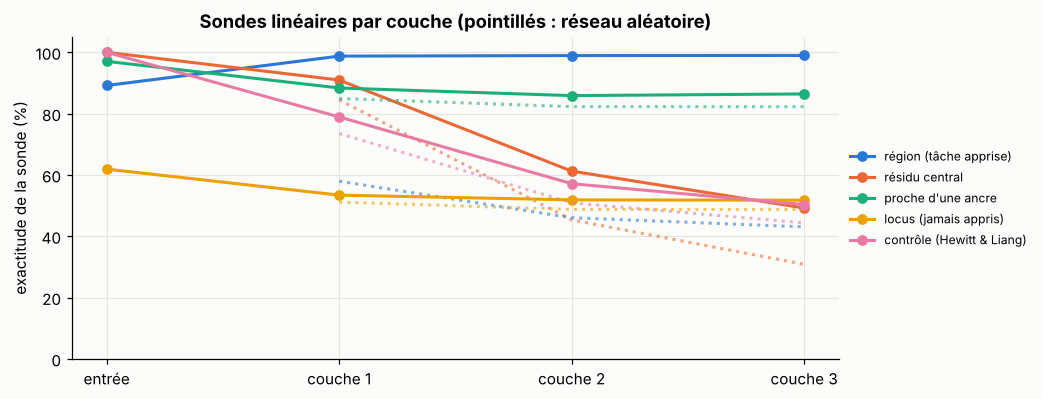

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for k, name in enumerate(targets):
    t = probes[(probes.target == name) & (probes.model == "entraîné")]
    ax.plot(t.layer, t.acc * 100, "o-", color=PALETTE[k], label=name)
    tr_ = probes[(probes.target == name) & (probes.model == "aléatoire")]
    ax.plot(tr_.layer, tr_.acc * 100, ":", color=PALETTE[k], alpha=0.6)
ax.set_ylabel("exactitude de la sonde (%)"); ax.set_ylim(0, 105)
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_title("Sondes linéaires par couche (pointillés : réseau aléatoire)")
plt.show()

Ce que montrent les sondes (à lire **toujours** contre deux références : la classe majoritaire et le réseau aléatoire) :
- la **région** passe de 89 % (lecture linéaire de la fenêtre brute) à 99 % dès la couche 1 : c'est la tâche apprise, et le réseau aléatoire plafonne vers 45–58 % ;
- l'**identité du résidu central**, parfaitement lisible à l'entrée, se **perd** au fil des couches (49 % en couche 3) : le réseau ne garde que ce qui sert la tâche ;
- le **contrôle** de Hewitt & Liang suit la même pente : une sonde qui « réussit » sur une couche précoce peut simplement y lire l'identité des résidus ;
- la **proximité d'une ancre** semble bien décodable (86 % en couche 3)… mais la classe majoritaire (« loin d'une ancre ») fait déjà environ 83 %, et le réseau aléatoire 82 % : la sonde n'apprend presque rien. Sans ces références, on aurait conclu à tort que le réseau code explicitement les ancres ;
- le **locus**, jamais appris, est lisible à 62 % dans la fenêtre brute mais retombe à 52–53 % dans les couches cachées, à peine au-dessus de la classe majoritaire (IGH, environ 49 %) : le réseau **jette** l'information dont il n'a pas besoin.

## 3. Attributions : gradients intégrés et occlusion

Une attribution répond à : « quelles entrées ont fait monter ce score ? ». Les **gradients intégrés** (Sundararajan et al., 2017) moyennent le gradient le long d'un chemin entre une **référence** $x'$ (ici : la fenêtre vide, tout à zéro) et l'entrée $x$ :

$$\text{IG}_i(x) = (x_i - x'_i) \int_0^1 \frac{\partial F(x' + \alpha (x - x'))}{\partial x_i} \, d\alpha,$$

approchée par une somme de Riemann. Propriété clé (**complétude**) : $\sum_i \text{IG}_i = F(x) - F(x')$. On l'utilise comme test de l'implémentation.

L'**occlusion** (ou mutagenèse *in silico*) est plus directe : on remplace un résidu de la fenêtre par d'autres acides aminés et on mesure la chute de probabilité. C'est la version « expérience » de l'attribution, plus coûteuse mais plus facile à interpréter.

In [6]:
def grad_logit(X, params, k):
    """d logit_k / d X for every row of X (manual backprop through the ReLU MLP)."""
    acts = forward(X, params)
    g = np.zeros_like(acts[-1]); g[:, k] = 1.0
    for i in range(len(params) - 1, -1, -1):
        g = g @ params[i][0].T
        if i > 0:
            g = g * (acts[i] > 0)
    return g


def integrated_gradients(X, params, k, steps=48):
    baseline = np.zeros_like(X)
    total = np.zeros_like(X)
    for a in (np.arange(steps) + 0.5) / steps:
        total += grad_logit(baseline + a * (X - baseline), params, k)
    return (X - baseline) * total / steps


def by_offset(attr):
    """Sum attributions over the 21 one-hot dims of each window offset -> (n, 17)."""
    return attr.reshape(len(attr), 2 * W + 1, K).sum(2)

# completeness check on a few residues
sel = np.flatnonzero(mte.pos.values == "27")[:50]
k = REGION_NAMES.index("CDR1")
ig = integrated_gradients(Xte[sel], params, k)
lhs = ig.sum(1)
rhs = forward(Xte[sel], params)[-1][:, k] - forward(np.zeros_like(Xte[sel]), params)[-1][:, k]
print(f"completeness: max |sum(IG) - (F(x) - F(x'))| = {np.abs(lhs - rhs).max():.4f}  (relative to mean |F(x)-F(x')| = {np.abs(rhs).mean():.2f})")

completeness: max |sum(IG) - (F(x) - F(x'))| = 0.0950  (relative to mean |F(x)-F(x')| = 16.50)


On regarde trois résidus « frontières » dont on connaît la logique IMGT : le **premier résidu du CDR1** (position 27, quatre positions après l'ancre C23), le **premier du FR2** (position 39, deux positions avant W41), et le **premier du CDR3** (position 105, juste après C104). Si le réseau a appris les règles, ses attributions doivent pointer vers ces ancres.

position 27: top-3 offsets by IG [np.int64(-4), np.int64(-3), np.int64(-8)], by occlusion [np.int64(-4), np.int64(-2), np.int64(-3)]
position 39: top-3 offsets by IG [np.int64(2), np.int64(-7), np.int64(8)], by occlusion [np.int64(2), np.int64(0), np.int64(1)]
position 105: top-3 offsets by IG [np.int64(-1), np.int64(0), np.int64(1)], by occlusion [np.int64(-1), np.int64(1), np.int64(0)]


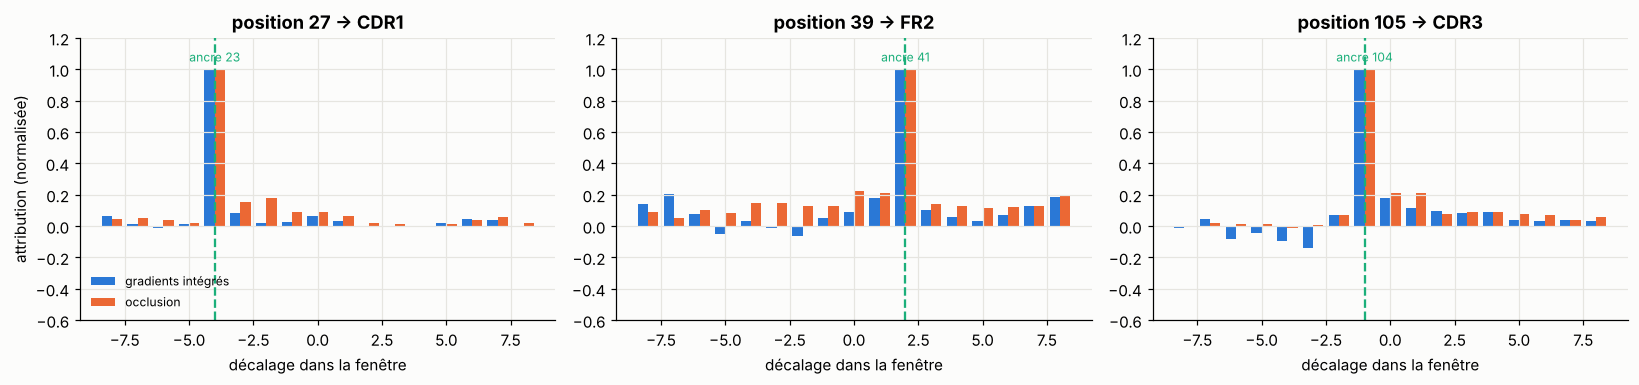

In [7]:
def occlusion(X, params, k, n_draws=6, seed=0):
    r = np.random.default_rng(seed)
    p0 = softmax(forward(X, params)[-1])[:, k]
    drops = np.zeros((len(X), 2 * W + 1))
    for o in range(2 * W + 1):
        for _ in range(n_draws):
            Xm = X.copy()
            Xm[:, o * K:(o + 1) * K] = 0
            Xm[np.arange(len(X)), o * K + r.integers(0, 20, len(X))] = 1
            drops[:, o] += (p0 - softmax(forward(Xm, params)[-1])[:, k]) / n_draws
    return drops

cases = [("27", "CDR1", 23), ("39", "FR2", 41), ("105", "CDR3", 104)]
offsets = np.arange(-W, W + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=False)
profiles = {}
for ax, (pos, region, anchor) in zip(axes, cases):
    sel = np.flatnonzero(mte.pos.values == pos)[:150]
    kk = REGION_NAMES.index(region)
    ig_prof = by_offset(integrated_gradients(Xte[sel], params, kk)).mean(0)
    occ_prof = occlusion(Xte[sel], params, kk).mean(0)
    profiles[pos] = (ig_prof, occ_prof)
    ax.bar(offsets - 0.2, ig_prof / np.abs(ig_prof).max(), 0.4, color=PALETTE[0], label="gradients intégrés")
    ax.bar(offsets + 0.2, occ_prof / np.abs(occ_prof).max(), 0.4, color=PALETTE[1], label="occlusion")
    ax.axvline(anchor - int(pos), color=PALETTE[2], ls="--", lw=1.5)
    ax.text(anchor - int(pos), 1.05, f"ancre {anchor}", color=PALETTE[2], ha="center", fontsize=8)
    ax.set_title(f"position {pos} → {region}"); ax.set_xlabel("décalage dans la fenêtre"); ax.set_ylim(-0.6, 1.2)
axes[0].set_ylabel("attribution (normalisée)"); axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()
for pos, (a, b) in profiles.items():
    print(f"position {pos}: top-3 offsets by IG {list(offsets[np.argsort(-a)[:3]])}, by occlusion {list(offsets[np.argsort(-b)[:3]])}")

## 4. Tester les attributions

Une carte d'attribution est une **hypothèse** sur le modèle, pas une observation. Deux tests simples permettent de rejeter les méthodes trompeuses :

1. **Test de randomisation du modèle** (Adebayo et al., 2018, *Sanity checks for saliency maps*) : si l'on remplace les poids entraînés par des poids aléatoires, l'attribution doit **changer**. Une méthode qui donne la même carte pour un modèle entraîné et un modèle aléatoire ne décrit pas le modèle (elle décrit l'entrée).
2. **Accord entre méthodes indépendantes** : gradients intégrés (analytique) et occlusion (expérimentale) doivent désigner les mêmes résidus importants. Un désaccord est un signal d'alerte.

In [8]:
from scipy.stats import spearmanr

rows_ = []
for pos, region, _ in cases:
    sel = np.flatnonzero(mte.pos.values == pos)[:150]
    kk = REGION_NAMES.index(region)
    ig_trained, occ = profiles[pos]
    ig_random = by_offset(integrated_gradients(Xte[sel], random_params, kk)).mean(0)
    rows_.append(dict(position=pos, IG_vs_occlusion=spearmanr(ig_trained, occ)[0],
                      IG_trained_vs_IG_random=spearmanr(ig_trained, ig_random)[0]))
print(pd.DataFrame(rows_).round(2).to_string(index=False))

position  IG_vs_occlusion  IG_trained_vs_IG_random
      27              0.7                    -0.03
      39              0.2                    -0.04
     105              0.9                    -0.10


Les deux méthodes désignent le **même résidu dominant** dans les trois cas, et c'est chaque fois l'ancre attendue : C23 pour le début du CDR1 (décalage −4), W41 pour le début du FR2 (+2), C104 pour le début du CDR3 (−1). La corrélation de rang sur l'ensemble du profil est forte pour les positions 27 et 105 (0,7 et 0,9), faible pour la position 39 (0,2) : hors de l'ancre, les petites attributions sont du bruit, et c'est sur le pic qu'il faut juger. Les attributions du modèle aléatoire n'ont rien à voir avec celles du modèle entraîné (corrélation proche de 0) : le test de randomisation est passé. Ces tests ne prouvent pas qu'une attribution est « vraie », ils éliminent les méthodes manifestement fausses.

## 5. Autoencodeurs parcimonieux : des neurones aux concepts

Un neurone isolé répond souvent à plusieurs choses à la fois (**polysémanticité**). L'hypothèse de **superposition** dit que le réseau encode plus de concepts qu'il n'a de dimensions, sous forme de **directions** presque orthogonales. Un **autoencodeur parcimonieux** (SAE) cherche ces directions : il réécrit chaque activation $a \in \mathbb{R}^{d}$ comme une combinaison **parcimonieuse** de $m \gg d$ directions apprises :

$$z = \text{TopK}\big(\text{ReLU}(W_e (a - b_d) + b_e)\big), \qquad \hat{a} = W_d z + b_d, \qquad \mathcal{L} = \lVert a - \hat{a} \rVert^2,$$

où TopK ne garde que les $k$ plus grandes activations de chaque exemple (variante « TopK » de Gao et al., 2024, qui fixe directement la parcimonie au lieu de la régler par une pénalité L1 difficile à calibrer), avec des colonnes de $W_d$ de norme 1. C'est la famille de méthodes utilisée par InterPLM (Simon & Zou, 2024) et d'autres travaux sur ESM-2 pour y trouver des caractéristiques liées aux motifs, domaines ou sites de liaison.

> 🧪 Une première version de ce notebook utilisait la pénalité L1 classique : avec $\lambda$ petit, chaque résidu activait environ la moitié des 256 caractéristiques (aucune parcimonie, aucun concept lisible) ; pour descendre à une vingtaine de caractéristiques actives, il fallait un $\lambda$ qui faisait tomber la variance expliquée à 83 %. La version TopK règle la parcimonie directement, ce qui est plus robuste.

On entraîne un SAE TopK à 256 caractéristiques, $k = 8$, sur les activations de la couche 2 (64 dimensions).

In [9]:
def topk_mask(pre, k):
    thr = np.partition(pre, -k, axis=1)[:, -k][:, None]
    return (pre >= thr) & (pre > 0)


def train_sae(A, m=256, k=8, epochs=15, lr=2e-3, seed=0):
    r = np.random.default_rng(seed)
    d = A.shape[1]
    Wd = r.normal(0, 1, (d, m)).astype(np.float32); Wd /= np.linalg.norm(Wd, axis=0, keepdims=True)
    P = [Wd.T.copy(), np.zeros(m, np.float32), Wd, A.mean(0).astype(np.float32)]      # We, be, Wd, bd
    M, V, t = [np.zeros_like(p) for p in P], [np.zeros_like(p) for p in P], 0
    for ep in range(epochs):
        perm = r.permutation(len(A))
        for s0 in range(0, len(A), 512):
            a = A[perm[s0:s0 + 512]]
            We, be, Wd, bd = P
            pre = (a - bd) @ We.T + be
            keep = topk_mask(pre, k)
            z = np.where(keep, pre, 0)
            g_a = 2 * (z @ Wd.T + bd - a) / len(a)          # d loss / d ahat
            g_pre = (g_a @ Wd) * keep                       # gradient only through the kept units
            grads = [g_pre.T @ (a - bd), g_pre.sum(0), g_a.T @ z, g_a.sum(0) - (g_pre @ We).sum(0)]
            t += 1
            for i, g in enumerate(grads):
                M[i] = 0.9 * M[i] + 0.1 * g; V[i] = 0.999 * V[i] + 0.001 * g ** 2
                P[i] = P[i] - lr * (M[i] / (1 - 0.9 ** t)) / (np.sqrt(V[i] / (1 - 0.999 ** t)) + 1e-8)
            P[2] = P[2] / np.maximum(np.linalg.norm(P[2], axis=0, keepdims=True), 1e-8)    # unit-norm decoder columns
    return P


def sae_encode(A, P, k=8):
    We, be, Wd, bd = P
    pre = (A - bd) @ We.T + be
    return np.where(topk_mask(pre, k), pre, 0)

A_tr = forward(Xtr, params)[2]
sae = train_sae(A_tr)
A_te = forward(Xte, params)[2]
Z = sae_encode(A_te, sae)
recon = Z @ sae[2].T + sae[3]
fvu = ((A_te - recon) ** 2).sum() / ((A_te - A_te.mean(0)) ** 2).sum()
alive = (Z > 0).any(0)
print(f"variance explained {1 - fvu:.3f} | active features per residue (L0) {(Z > 0).sum(1).mean():.1f} | "
      f"alive features {alive.sum()}/{Z.shape[1]}")

variance explained 0.893 | active features per residue (L0) 8.0 | alive features 256/256


Pour **nommer** une caractéristique, on regarde où elle s'active : ici, en fonction de la position IMGT. Une caractéristique « monosémantique » s'active sur peu de positions voisines ; on la mesure par la part de son activation totale concentrée sur sa position préférée (± 1).

peak positions of the 14 most localized features: [1, 17, 23, 24, 29, 47, 48, 49, 52, 103, 105, 125, 127, 127]


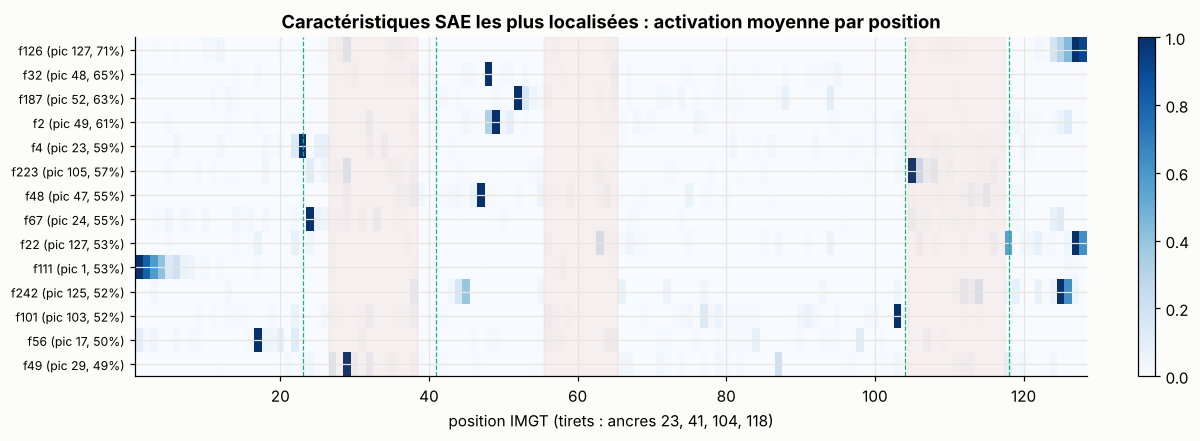

In [10]:
pos_bins = np.clip(mte.base.values, 1, 128)
mean_by_pos = np.zeros((Z.shape[1], 128))
for p in range(1, 129):
    sel = pos_bins == p
    if sel.any():
        mean_by_pos[:, p - 1] = Z[sel].mean(0)
total = mean_by_pos.sum(1) + 1e-9
peak = mean_by_pos.argmax(1)
concentration = np.array([mean_by_pos[f, max(0, p - 1):p + 2].sum() / total[f] for f, p in enumerate(peak)])
order = [f for f in np.argsort(-concentration) if alive[f]][:14]
fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(mean_by_pos[order] / mean_by_pos[order].max(1, keepdims=True), aspect="auto", cmap="Blues",
               extent=[0.5, 128.5, len(order) - 0.5, -0.5])
for name, s, e in [("CDR1", 27, 38), ("CDR2", 56, 65), ("CDR3", 105, 117)]:
    ax.axvspan(s - 0.5, e + 0.5, color=PALETTE[1], alpha=0.08)
for a in (23, 41, 104, 118):
    ax.axvline(a, color=PALETTE[2], lw=0.8, ls="--")
ax.set_yticks(range(len(order))); ax.set_yticklabels([f"f{f} (pic {peak[f] + 1}, {concentration[f]:.0%})" for f in order], fontsize=8)
ax.set_xlabel("position IMGT (tirets : ancres 23, 41, 104, 118)"); ax.set_title("Caractéristiques SAE les plus localisées : activation moyenne par position")
plt.colorbar(im, ax=ax, fraction=0.02); plt.show()
print("peak positions of the 14 most localized features:", sorted(int(peak[f] + 1) for f in order))

Ce que le SAE a trouvé, sans aucune supervision :
- des caractéristiques calées sur les **ancres** et leur voisinage immédiat : position 23 (1st-CYS), 24, 103 et 105 (de part et d'autre de la 2nd-CYS 104, donc la frontière FR3/CDR3) ;
- des caractéristiques de **bord de domaine** (positions 1 et 125–128) : elles détectent le remplissage de la fenêtre au début et à la fin de la séquence. C'est un **artefact de l'encodage** de l'entrée, l'équivalent des caractéristiques liées à `<cls>` et `<eos>` dans un PLM ; il faut les reconnaître pour ne pas les sur-interpréter ;
- un groupe dans le **FR2 (positions 47–52)** qui ne correspond à aucune frontière IMGT. C'est typiquement là qu'un SAE est utile : il suggère une **hypothèse** (un motif conservé dans certaines familles ?) qu'il faut ensuite vérifier sur les données.

C'est le type de figure que l'on peut montrer dans un article, **à condition** de la confirmer par un test causal.

## 6. Tests causaux : ablation de concepts

Une caractéristique décodable n'est pas forcément **utilisée**. Test : on **retire** une caractéristique (on met son activation à zéro dans la reconstruction), on fait passer la reconstruction modifiée dans la suite du réseau, et on mesure l'effet sur les prédictions, **là où la caractéristique est active** et ailleurs. On compare à l'ablation de caractéristiques prises au hasard (contrôle).

In [11]:
def downstream(A2, params):
    """Run layer 3 and the output layer from layer-2 activations; returns class probabilities."""
    h = np.maximum(A2 @ params[2][0] + params[2][1], 0)
    return softmax(h @ params[3][0] + params[3][1])

base_p = downstream(Z @ sae[2].T + sae[3], params)
p_true = base_p[np.arange(len(yte)), yte]
print(f"accuracy with SAE reconstruction instead of true activations: {(base_p.argmax(1) == yte).mean():.4f} "
      f"(original {(acts_te[-1].argmax(1) == yte).mean():.4f})")


def ablation_effect(f):
    """Mean drop of p(true region) where feature f is strongly active, and elsewhere."""
    Z2 = Z.copy(); Z2[:, f] = 0
    p2 = downstream(Z2 @ sae[2].T + sae[3], params)[np.arange(len(yte)), yte]
    active = Z[:, f] > 0.5 * Z[:, f].max()
    return active, (p_true - p2)[active].mean(), (p_true - p2)[~active].mean()

rows_ = []
for f in order[:8]:
    active, d_in, d_out = ablation_effect(f)
    rows_.append(dict(feature=f"f{f}", peak_position=int(peak[f] + 1), n_active=int(active.sum()),
                      drop_p_true_where_active=d_in, drop_p_true_elsewhere=d_out))
ctrl = [ablation_effect(int(f))[1] for f in rng.choice(np.flatnonzero(alive), 30, replace=False)]
print(pd.DataFrame(rows_).round(4).to_string(index=False))
print(f"control (30 random features): mean drop of p(true) where active = {np.nanmean(ctrl):.4f}")

accuracy with SAE reconstruction instead of true activations: 0.9839 (original 0.9893)
feature  peak_position  n_active  drop_p_true_where_active  drop_p_true_elsewhere
   f126            127       278                    0.0000                 0.0000
    f32             48        66                    0.0296                 0.0001
   f187             52        71                    0.0155                 0.0001
     f2             49        90                    0.0108                 0.0000
     f4             23        79                    0.0002                 0.0000
   f223            105        95                    0.0052                 0.0000
    f48             47        97                    0.0779                 0.0000
    f67             24        86                    0.0027                 0.0000
control (30 random features): mean drop of p(true) where active = 0.0465


Le résultat est instructif, et il va à l'encontre de l'intuition :
- les effets sont bien **locaux** : retirer une caractéristique ne change presque rien là où elle est inactive ;
- mais les caractéristiques les plus **lisibles** (les plus localisées) ont des effets **faibles** (de 0 à 0,08 de probabilité perdue), en moyenne **plus faibles** que des caractéristiques prises au hasard (0,047) ! Les ancres sont codées de façon **redondante** : retirer une seule caractéristique « C23 » ne suffit pas à faire douter le réseau, d'autres prennent le relais.

Leçon générale : **lisible ne veut pas dire important**. Une caractéristique peut décrire parfaitement une propriété sans peser sur la décision, et inversement. C'est précisément pour cela qu'un article d'interprétabilité doit montrer des **tests causaux avec contrôle**, et pas seulement de belles cartes d'activation. Pour tester un concept redondant, on ablate **ensemble** toutes les caractéristiques qui le codent (exercice 2).

## 7. Sur un vrai PLM : ESM-2, attention, contacts, Captum, SAE

Les mêmes outils s'appliquent à ESM-2 ou à ton modèle ProtAnnotML. Trois recettes.

### 7.1 Couches cachées et sondes

In [ ]:
import torch
from transformers import AutoTokenizer, EsmModel
from sklearn.linear_model import LogisticRegression

name = "facebook/esm2_t12_35M_UR50D"
tok, esm = AutoTokenizer.from_pretrained(name), EsmModel.from_pretrained(name, add_pooling_layer=False).eval()


@torch.no_grad()
def layer_states(seqs, batch=16):
    """List over layers of (n_residues, H) arrays, residues only (no <cls>/<eos>/padding)."""
    per_layer = None
    for k in range(0, len(seqs), batch):
        chunk = seqs[k:k + batch]
        enc = tok(chunk, padding=True, return_tensors="pt")
        out = esm(**enc, output_hidden_states=True)
        if per_layer is None:
            per_layer = [[] for _ in out.hidden_states]
        for li, h in enumerate(out.hidden_states):               # embeddings + one entry per layer
            for i, s in enumerate(chunk):
                per_layer[li].append(h[i, 1:1 + len(s)].float().numpy())
    return [np.concatenate(x) for x in per_layer]

# probe each layer for the region label (seqs, labels from the capstone data)
# H = layer_states(train_seqs); Ht = layer_states(test_seqs)
# accs = [LogisticRegression(max_iter=500).fit(H[l], y_train).score(Ht[l], y_test) for l in range(len(H))]

### 7.2 Attention et contacts : le pont disulfure C23–C104

Rao et al. (2021) ont montré qu'une régression logistique sur les cartes d'attention d'un PLM prédit les **contacts** de la structure 3D sans jamais l'avoir vue. Dans un domaine V, le contact le plus célèbre est le **pont disulfure** entre la 1st-CYS 23 et la 2nd-CYS 104, à environ 80 résidus de distance dans la séquence. Le test est simple et parlant pour un article : la probabilité de contact prédite entre ces deux cystéines doit être parmi les plus élevées.

In [ ]:
from transformers import EsmForMaskedLM

mlm = EsmForMaskedLM.from_pretrained("facebook/esm2_t33_650M_UR50D").eval()
tok650 = AutoTokenizer.from_pretrained("facebook/esm2_t33_650M_UR50D")


@torch.no_grad()
def contact_map(seq):
    enc = tok650(seq, return_tensors="pt")
    return mlm.esm.predict_contacts(enc["input_ids"], enc["attention_mask"])[0].numpy()   # (L, L), residues only


def cys_bridge_rank(seq, imgt_positions):
    """Rank of the C23-C104 contact among all pairs with |i - j| >= 24 (1 = most probable)."""
    C = contact_map(seq)
    i, j = imgt_positions.index("23"), imgt_positions.index("104")
    L = len(seq)
    mask = np.abs(np.arange(L)[:, None] - np.arange(L)[None, :]) >= 24
    scores = C[mask]
    return int((scores > C[i, j]).sum() // 2 + 1), float(C[i, j])

# rank, p = cys_bridge_rank(seq, imgt_pos)   -> expect rank 1-3 and p > 0.5 for well-folded V domains

> ⚠️ **L'attention n'est pas une explication.** Les poids d'attention disent où une tête « regarde », pas ce qui **cause** la prédiction (Jain & Wallace, 2019 ; Wiegreffe & Pinter, 2019). La prédiction de contacts est une **sonde** sur les cartes d'attention, pas une attribution. Pour une attribution, utilise les gradients intégrés ou l'occlusion.

### 7.3 Gradients intégrés avec Captum sur ProtAnnotML

Sur un modèle à tokens discrets, on intègre le long d'un chemin dans l'espace des **plongements** : `LayerIntegratedGradients` sur la couche d'embeddings, avec une référence (ici des tokens `<mask>` aux positions des résidus). La cible est le logit d'une classe de position IMGT pour un résidu donné.

In [ ]:
from captum.attr import LayerIntegratedGradients


def position_attributions(model, tok, seq, residue_index, position_class, n_steps=64):
    """Attribution of each residue to the logit of `position_class` at `residue_index` (ProtAnnotModel)."""
    model.eval()
    enc = tok([seq], return_tensors="pt")
    residue_mask = torch.ones(1, len(seq), dtype=torch.bool)
    baseline = enc["input_ids"].clone()
    baseline[0, 1:1 + len(seq)] = tok.mask_token_id                        # keep <cls>/<eos>, mask the residues

    def forward_fn(input_ids, attention_mask, residue_mask):
        out = model(input_ids, attention_mask, residue_mask)
        return out["pos_logits"][:, residue_index, position_class]

    lig = LayerIntegratedGradients(forward_fn, model.backbone.embeddings)
    attr, delta = lig.attribute(enc["input_ids"], baselines=baseline, n_steps=n_steps,
                                additional_forward_args=(enc["attention_mask"], residue_mask),
                                return_convergence_delta=True)
    per_residue = attr.sum(-1)[0, 1:1 + len(seq)].detach().numpy()            # sum over embedding dimensions
    return per_residue, float(delta)                                          # check |delta| is small (completeness)

> Remarque technique : ESM-2 applique une remise à l'échelle des plongements selon la proportion de tokens `<mask>` (*token dropout*), y compris à l'inférence. Avec une référence entièrement masquée, cette remise à l'échelle change le long du chemin : vérifie la convergence (`delta`) et compare avec une référence en `<pad>` ou en acide aminé « moyen ».

### 7.4 Un SAE sur une couche d'ESM-2

Version L1 (la plus simple ; remplace la pénalité par un TopK comme en section 5 si la parcimonie est difficile à régler) :

In [ ]:
import torch.nn as nn


class SAE(nn.Module):
    def __init__(self, d, m):
        super().__init__()
        self.enc = nn.Linear(d, m)
        self.dec = nn.Linear(m, d)
        with torch.no_grad():
            self.dec.weight /= self.dec.weight.norm(dim=0, keepdim=True)

    def forward(self, a):
        z = torch.relu(self.enc(a - self.dec.bias))
        return self.dec(z), z


def train_sae_torch(acts, m=8 * 480, lam=5e-4, epochs=5, lr=1e-3, device="cuda"):
    """acts: (N, H) float tensor of residue states from one ESM-2 layer (millions of residues in practice)."""
    sae = SAE(acts.shape[1], m).to(device)
    opt = torch.optim.Adam(sae.parameters(), lr=lr)
    for _ in range(epochs):
        for batch in torch.split(acts[torch.randperm(len(acts))], 4096):
            a = batch.to(device)
            ahat, z = sae(a)
            loss = ((ahat - a) ** 2).sum(-1).mean() + lam * z.abs().sum(-1).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad():
                sae.dec.weight /= sae.dec.weight.norm(dim=0, keepdim=True)
    return sae

Pour ProtAnnotML, la question intéressante est : existe-t-il des caractéristiques d'ESM-2 (avant affinage) qui codent déjà les frontières FR/CDR ou les ancres IMGT ? Et l'affinage les renforce-t-il ? Une figure « caractéristique × position IMGT » avant et après DAPT est un bon matériau pour la discussion d'un article.

## 8. Pièges et bonnes pratiques

| Piège | Conséquence | Parade |
|---|---|---|
| Sonde trop puissante | elle apprend la tâche au lieu de lire la couche | sonde linéaire, tâche de contrôle, sélectivité |
| Décodable = utilisé | conclusion causale sans preuve | ablation / *patching* avec contrôle aléatoire |
| Carte de saillance non testée | elle peut ne pas dépendre du modèle | test de randomisation, accord IG / occlusion |
| Référence (*baseline*) arbitraire | les gradients intégrés changent avec la référence | justifier la référence, en essayer deux |
| Attention = explication | confusion entre « regarder » et « causer » | attention comme sonde (contacts), pas comme attribution |
| Choix *a posteriori* des exemples | biais de confirmation | sélection systématique (toutes les séquences d'une strate), exemples tirés au hasard |
| SAE : caractéristiques mortes ou trop denses | concepts illisibles | suivre L0, variance expliquée, part de caractéristiques actives |

## 9. Récapitulatif

| Outil | Question | Validation indispensable |
|---|---|---|
| Sonde linéaire | l'information est-elle décodable dans cette couche ? | tâche de contrôle, modèle aléatoire |
| Gradients intégrés | quelles entrées font monter ce score ? | complétude, randomisation, accord avec l'occlusion |
| Occlusion / mutagenèse | que se passe-t-il si je change ce résidu ? | plusieurs remplacements, effet moyen |
| SAE | quels « concepts » le modèle utilise-t-il ? | variance expliquée, L0, caractéristiques mortes |
| Ablation | ce concept sert-il à la décision ? | effet local vs ailleurs, contrôle aléatoire |
| Contacts depuis l'attention | la structure est-elle encodée ? | contacts connus (C23–C104), comparaison avec des structures |

### 🏋️ Exercices

1. **Ancres et mutations.** Mute *in silico* C23 en S dans 100 domaines de test : comment changent les prédictions de régions autour du CDR1 ? Le modèle « casse-t-il » proprement, ou devient-il silencieusement faux ?
2. **SAE : taille, parcimonie, redondance.** Entraîne des SAE avec $m \in \{64, 256, 1024\}$ et $k \in \{4, 8, 16\}$ ; trace la variance expliquée en fonction de $k$. Puis ablate **ensemble** toutes les caractéristiques dont le pic est entre 22 et 24 : l'effet sur le début du CDR1 devient-il important ?
3. **ESM-2.** Avec la recette 7.2, mesure le rang du contact C23–C104 sur 50 domaines V réels de différentes espèces. Le rang se dégrade-t-il pour les espèces peu représentées dans UniRef ?
4. **ProtAnnotML.** Après l'affinage (fil rouge 4), calcule les gradients intégrés pour la classe « position 105 » sur le premier résidu du CDR3. Le modèle regarde-t-il C104 (comme ici) ou d'autres indices ?

<details><summary>Indications</summary>

1. Compare la perte d'exactitude à la baisse de confiance (probabilité maximale) : un modèle bien calibré doit devenir **moins sûr** quand une ancre disparaît.
3. Pour une évaluation propre, compare au rang moyen d'une paire de cystéines **non** liées à distance similaire.
</details>